# U-Net com encoder ResNet34 para segmentação de floresta nativa

Neste notebook, vamos treinar um modelo de **segmentação semântica binária** para identificar **floresta nativa** em imagens exportadas/anotadas no Roboflow.

A ideia do treinamento será:

- `0 = fundo/outros`
- `1 = floresta_nativa`

As máscaras usadas neste experimento já estão em formato binário:

```python
0  ->  fundo/outros
1  ->  floresta_nativa
```

A arquitetura usada será uma **U-Net com encoder ResNet34 pré-treinado no ImageNet**, usando a biblioteca `segmentation_models_pytorch`.

## Bloco 1 — Instalar bibliotecas

Este bloco instala as bibliotecas necessárias para o treinamento.

- `segmentation-models-pytorch`: facilita criar U-Net com encoder ResNet.
- `torch` e `torchvision`: base do deep learning em PyTorch.
- `albumentations`: usada para aplicar transformações iguais na imagem e na máscara.
- `opencv-python`: leitura e manipulação de imagens.
- `matplotlib`: visualização dos resultados.
- `tqdm`: barra de progresso durante o treinamento.

In [1]:
!pip install segmentation-models-pytorch albumentations opencv-python torch torchvision matplotlib tqdm -q

## Bloco 2 — Importar bibliotecas

Aqui carregamos todos os pacotes que serão usados no notebook.

A biblioteca principal do modelo será `segmentation_models_pytorch`, abreviada como `smp`.

In [1]:
# Bibliotecas gerais
import os
import random
from pathlib import Path

# Manipulação numérica e imagens
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Transformações para segmentação
import albumentations as A
from albumentations.pytorch import ToTensorV2

# Modelos de segmentação prontos
import segmentation_models_pytorch as smp

# Barra de progresso
from tqdm.auto import tqdm

c:\Users\Ola\anaconda3\envs\visao_computacional\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Bloco 3 — Configurações iniciais

Neste bloco definimos os principais parâmetros do experimento.

A estrutura esperada do dataset é:

```text
dataset/
├── train/
│   ├── images/
│   └── masks/
├── val/
│   ├── images/
│   └── masks/
└── test/
    ├── images/
    └── masks/
```

As imagens podem estar nos formatos `.jpg`, `.jpeg` ou `.png`. As máscaras devem estar na pasta `masks` e manter o sufixo `_mask`, por exemplo:

```text
imagem.png
imagem_mask.png
```


In [2]:
# Caminho principal do dataset.
# Ajuste este caminho para a pasta onde você colocou o dataset.
DATASET_DIR = Path("dataset")

# Subpastas do dataset.
TRAIN_IMAGES_DIR = DATASET_DIR / "train" / "images"
TRAIN_MASKS_DIR  = DATASET_DIR / "train" / "masks"

VAL_IMAGES_DIR = DATASET_DIR / "val" / "images"
VAL_MASKS_DIR  = DATASET_DIR / "val" / "masks"

TEST_IMAGES_DIR = DATASET_DIR / "test" / "images"
TEST_MASKS_DIR  = DATASET_DIR / "test" / "masks"

# Tamanho usado no treinamento.
# O Resize padroniza as imagens e máscaras para 512x512.
IMG_SIZE = 512

# Parâmetros do treinamento.
BATCH_SIZE = 2
NUM_EPOCHS = 50
LEARNING_RATE = 1e-4

# Define se o treinamento vai rodar em GPU ou CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo usado:", DEVICE)

Dispositivo usado: cpu


## Bloco 4 — Fixar semente aleatória


In [3]:
def set_seed(seed=42):
    """Fixa sementes aleatórias para facilitar a reprodução dos resultados."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Estas opções reduzem aleatoriedade em algumas operações da GPU.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

## Bloco 5 — Criar transformações para imagem e máscara

Como estamos fazendo segmentação, a imagem e a máscara precisam receber transformações geométricas iguais.

Por isso usamos `Albumentations`, que aplica a mesma rotação/flip na imagem e na máscara.

Para o treinamento, usamos aumentos simples:

- flip horizontal;
- flip vertical;
- rotação de 90°;
- normalização compatível com ImageNet.

Para validação e teste, usamos apenas redimensionamento e normalização.

In [4]:
# Normalização usada por modelos pré-treinados no ImageNet.
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

# Transformações para treino.
# As transformações geométricas aumentam a variação dos dados.
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2()
])

# Transformações para validação e teste.
# Aqui não usamos aleatoriedade, apenas padronização.
val_test_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2()
])

## Bloco 6 — Criar o Dataset Loader

Este é um dos blocos mais importantes do notebook.

Ele faz quatro tarefas principais:

1. Lista as imagens da pasta `images`, aceitando arquivos `.jpg`, `.jpeg` e `.png`.
2. Encontra a máscara correspondente na pasta `masks`.
3. Lê imagem e máscara.
4. Garante que a máscara esteja em formato binário:

```text
0 = fundo/outros
1 = floresta_nativa
```

Como o Roboflow exporta as máscaras com sufixo `_mask`, o código procura automaticamente nomes como:

```text
imagem.png
imagem_mask.png
```


In [5]:
class RoboflowSegmentationDataset(Dataset):
    """
    Dataset personalizado para segmentação semântica usando imagens e máscaras exportadas pelo Roboflow.

    Estrutura esperada:
        split/images/arquivo.png
        split/masks/arquivo_mask.png

    Para este experimento:
        mask == 1  -> floresta_nativa
        mask == 0  -> fundo/outros
    """

    def __init__(self, images_dir, masks_dir, transform=None):
        self.images_dir = Path(images_dir)
        self.masks_dir = Path(masks_dir)
        self.transform = transform
        # Lista imagens comuns, ignorando qualquer arquivo que por acaso tenha _mask no nome.
        valid_exts = ["*.jpg", "*.jpeg", "*.png"]
        image_paths = []
        for ext in valid_exts:
            image_paths.extend(self.images_dir.glob(ext))

        self.image_paths = sorted([
            p for p in image_paths
            if not p.stem.endswith("_mask")
        ])

        if len(self.image_paths) == 0:
            raise FileNotFoundError(f"Nenhuma imagem JPG, JPEG ou PNG encontrada em: {self.images_dir}")

    def __len__(self):
        """Retorna o número de imagens no dataset."""
        return len(self.image_paths)

    def _find_mask_path(self, image_path):
        """
        Encontra a máscara correspondente à imagem.

        Exemplo:
            imagem: imagem1_patch_0_png.rf.ABC123.png
            máscara: imagem1_patch_0_png.rf.ABC123_mask.png
        """
        mask_name = image_path.stem + "_mask.png"
        mask_path = self.masks_dir / mask_name

        if not mask_path.exists():
            raise FileNotFoundError(
                f"Máscara não encontrada para a imagem: {image_path.name}"
            )

        return mask_path

    def __getitem__(self, idx):
        """Carrega uma imagem e sua máscara binária correspondente."""
        image_path = self.image_paths[idx]
        mask_path = self._find_mask_path(image_path)

        # Lê a imagem em RGB.
        image = cv2.imread(str(image_path))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # Lê a máscara preservando os valores originais dos pixels.
        mask = cv2.imread(str(mask_path), cv2.IMREAD_UNCHANGED)

        # Se a máscara vier com 3 canais, usamos o primeiro canal.
        # Em PNG mask, os valores de classe costumam estar em um canal só.
        if mask.ndim == 3:
            mask = mask[:, :, 0]

        # As máscaras já estão em formato binário:
        # 1 = floresta_nativa; 0 = fundo/outros.
        mask = (mask > 0).astype("float32")

        # Aplica transformações na imagem e na máscara ao mesmo tempo.
        if self.transform is not None:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask = augmented["mask"]

        # A U-Net com BCEWithLogitsLoss espera máscara no formato [1, H, W].
        mask = mask.unsqueeze(0).float()

        return image, mask

## Bloco 7 — Criar datasets e dataloaders

Aqui criamos os objetos que vão alimentar o modelo durante o treinamento.

O `DataLoader` permite carregar os dados em lotes (`batch_size`) e embaralhar o conjunto de treino.

In [6]:
# Cria os datasets para treino, validação e teste.
train_dataset = RoboflowSegmentationDataset(
    images_dir=TRAIN_IMAGES_DIR,
    masks_dir=TRAIN_MASKS_DIR,
    transform=train_transform
)

val_dataset = RoboflowSegmentationDataset(
    images_dir=VAL_IMAGES_DIR,
    masks_dir=VAL_MASKS_DIR,
    transform=val_test_transform
)

test_dataset = RoboflowSegmentationDataset(
    images_dir=TEST_IMAGES_DIR,
    masks_dir=TEST_MASKS_DIR,
    transform=val_test_transform
)

# Cria os dataloaders.
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("Imagens de treino:", len(train_dataset))
print("Imagens de validação:", len(val_dataset))
print("Imagens de teste:", len(test_dataset))

Imagens de treino: 10
Imagens de validação: 3
Imagens de teste: 2


## Bloco 8 — Conferir se imagem e máscara estão corretas

Antes de treinar, é essencial verificar se o carregamento está correto.

Aqui vamos conferir:

- formato das imagens;
- formato das máscaras;
- valores mínimo e máximo da máscara;
- visualização lado a lado.

In [7]:
# Pega um lote do treinamento para verificar os formatos.
images, masks = next(iter(train_loader))

print("Formato das imagens:", images.shape)
print("Formato das máscaras:", masks.shape)
print("Valor mínimo da máscara:", masks.min().item())
print("Valor máximo da máscara:", masks.max().item())
print("Valores únicos aproximados na máscara:", torch.unique(masks))

Formato das imagens: torch.Size([2, 3, 512, 512])
Formato das máscaras: torch.Size([2, 1, 512, 512])
Valor mínimo da máscara: 0.0
Valor máximo da máscara: 1.0
Valores únicos aproximados na máscara: tensor([0., 1.])


## Bloco 9 — Visualizar imagem e máscara

Este bloco desfaz a normalização da imagem apenas para visualização.

A máscara é exibida com uma paleta binária para facilitar a interpretação:

- preto = fundo/outros;
- azul = floresta nativa.


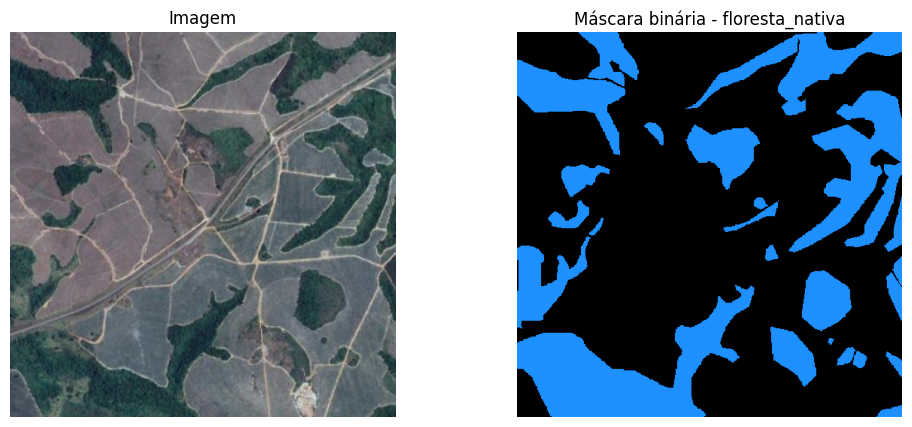

In [11]:
MASK_CMAP = ListedColormap(["black", "dodgerblue"])

def denormalize_image(tensor_image):
    """Desfaz a normalização ImageNet para visualizar a imagem corretamente."""
    image = tensor_image.permute(1, 2, 0).cpu().numpy()
    image = image * np.array(IMAGENET_STD) + np.array(IMAGENET_MEAN)
    image = np.clip(image, 0, 1)
    return image

# Seleciona a primeira imagem do lote.
idx = 1
image_vis = denormalize_image(images[idx])
mask_vis = masks[idx, 0].cpu().numpy()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_vis)
plt.title("Imagem")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_vis, cmap=MASK_CMAP, vmin=0, vmax=1)
plt.title("Máscara binária - floresta_nativa")
plt.axis("off")

plt.show()

## Bloco 10 — Criar o modelo U-Net com encoder ResNet34

Aqui criamos a arquitetura principal.

Configuração usada:

- `encoder_name="resnet34"`: usa ResNet34 como extrator de características.
- `encoder_weights="imagenet"`: usa pesos pré-treinados no ImageNet.
- `in_channels=3`: imagem RGB.
- `classes=1`: saída binária.
- `activation=None`: a ativação será aplicada depois com `sigmoid` apenas na inferência.

Durante o treino, usamos `BCEWithLogitsLoss`, que espera os logits brutos do modelo.

In [12]:
# Cria uma U-Net com encoder ResNet34 pré-treinado.
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
)

# Envia o modelo para GPU ou CPU.
model = model.to(DEVICE)

print(model.__class__.__name__)

Unet


## Bloco 11 — Definir função de perda, otimizador e métrica

Como o problema é binário, usamos:

- `BCEWithLogitsLoss`: perda para segmentação binária;
- `Adam`: otimizador;
- IoU binário: métrica para avaliar a sobreposição entre máscara real e predita.

A IoU é calculada após aplicar `sigmoid` e limiar de 0,5.

In [13]:
# Função de perda para segmentação binária.
criterion = nn.BCEWithLogitsLoss()

# Otimizador.
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)


def binary_iou_from_logits(logits, targets, threshold=0.5, eps=1e-7):
    """
    Calcula IoU binário a partir dos logits do modelo.

    logits: saída bruta do modelo, formato [B, 1, H, W]
    targets: máscara real, formato [B, 1, H, W]
    """
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) - intersection

    iou = (intersection + eps) / (union + eps)
    return iou.mean()

## Bloco 12 — Funções de treino e validação

Aqui definimos duas funções:

- `train_one_epoch`: treina o modelo por uma época.
- `validate_one_epoch`: avalia o modelo no conjunto de validação.

Cada função retorna:

- perda média;
- IoU média.

In [14]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    """Treina o modelo por uma época."""
    model.train()

    total_loss = 0.0
    total_iou = 0.0

    for images, masks in tqdm(loader, desc="Treino", leave=False):
        images = images.to(device)
        masks = masks.to(device)

        # Zera gradientes antigos.
        optimizer.zero_grad()

        # Forward: gera predições.
        logits = model(images)

        # Calcula perda.
        loss = criterion(logits, masks)

        # Backpropagation.
        loss.backward()
        optimizer.step()

        # Calcula IoU do lote.
        iou = binary_iou_from_logits(logits.detach(), masks)

        total_loss += loss.item()
        total_iou += iou.item()

    mean_loss = total_loss / len(loader)
    mean_iou = total_iou / len(loader)

    return mean_loss, mean_iou


@torch.no_grad()
def validate_one_epoch(model, loader, criterion, device):
    """Avalia o modelo em validação ou teste."""
    model.eval()

    total_loss = 0.0
    total_iou = 0.0

    for images, masks in tqdm(loader, desc="Validação", leave=False):
        images = images.to(device)
        masks = masks.to(device)

        # Forward sem cálculo de gradiente.
        logits = model(images)
        loss = criterion(logits, masks)
        iou = binary_iou_from_logits(logits, masks)

        total_loss += loss.item()
        total_iou += iou.item()

    mean_loss = total_loss / len(loader)
    mean_iou = total_iou / len(loader)

    return mean_loss, mean_iou

## Bloco 13 — Treinar o modelo

Este bloco executa o treinamento completo.

Também salvamos o melhor modelo com base na maior IoU de validação.

In [15]:
best_val_iou = 0.0
history = {
    "train_loss": [],
    "train_iou": [],
    "val_loss": [],
    "val_iou": []
}

for epoch in range(NUM_EPOCHS):
    train_loss, train_iou = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE)
    val_loss, val_iou = validate_one_epoch(model, val_loader, criterion, DEVICE)

    history["train_loss"].append(train_loss)
    history["train_iou"].append(train_iou)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)

    print(
        f"Época [{epoch+1}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train IoU: {train_iou:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val IoU: {val_iou:.4f}"
    )

    # Salva o melhor modelo pela IoU de validação.
    if val_iou > best_val_iou:
        best_val_iou = val_iou
        torch.save(model.state_dict(), "melhor_modelo_unet_resnet34_nativa.pth")
        print("  -> Melhor modelo salvo!")

print("Melhor IoU de validação:", best_val_iou)

Época [1/50] | Train Loss: 0.7513 | Train IoU: 0.3895 | Val Loss: 0.6995 | Val IoU: 0.4019
  -> Melhor modelo salvo!


Época [2/50] | Train Loss: 0.6180 | Train IoU: 0.4775 | Val Loss: 0.6263 | Val IoU: 0.4678
  -> Melhor modelo salvo!


Época [3/50] | Train Loss: 0.5459 | Train IoU: 0.5483 | Val Loss: 0.5860 | Val IoU: 0.5053
  -> Melhor modelo salvo!


Época [4/50] | Train Loss: 0.5013 | Train IoU: 0.6068 | Val Loss: 0.5779 | Val IoU: 0.5143
  -> Melhor modelo salvo!


Época [5/50] | Train Loss: 0.4486 | Train IoU: 0.6728 | Val Loss: 0.5644 | Val IoU: 0.5343
  -> Melhor modelo salvo!


...

Época [46/50] | Train Loss: 0.1566 | Train IoU: 0.8894 | Val Loss: 0.2585 | Val IoU: 0.8076


Época [47/50] | Train Loss: 0.1445 | Train IoU: 0.8994 | Val Loss: 0.2562 | Val IoU: 0.8084


Época [48/50] | Train Loss: 0.1492 | Train IoU: 0.8975 | Val Loss: 0.2568 | Val IoU: 0.8076


Época [49/50] | Train Loss: 0.1452 | Train IoU: 0.9038 | Val Loss: 0.2539 | Val IoU: 0.8081


Época [50/50] | Train Loss: 0.1567 | Train IoU: 0.8843 | Val Loss: 0.2570 | Val IoU: 0.8069
Melhor IoU de validação: 0.8129905462265015


## Bloco 14 — Visualizar curvas de treinamento

Aqui mostramos a evolução da perda e da IoU ao longo das épocas.

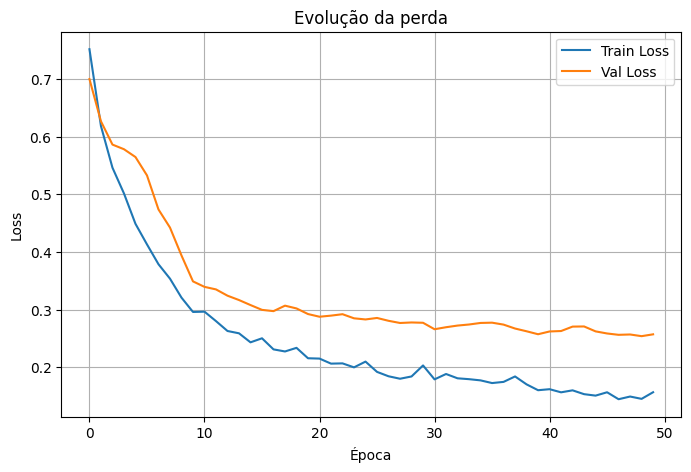

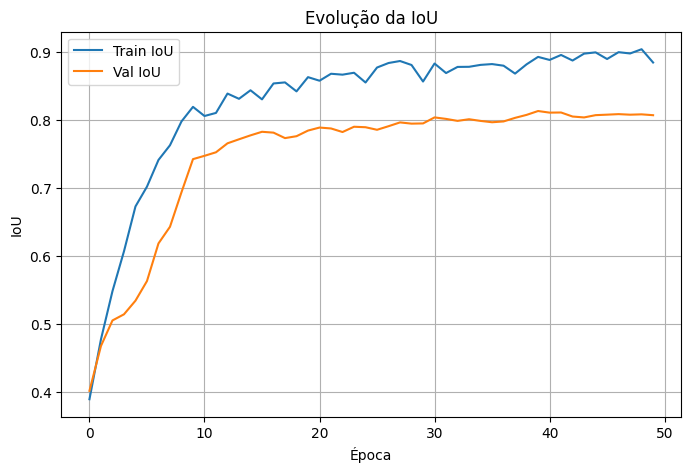

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Val Loss")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da perda")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history["train_iou"], label="Train IoU")
plt.plot(history["val_iou"], label="Val IoU")
plt.xlabel("Época")
plt.ylabel("IoU")
plt.title("Evolução da IoU")
plt.legend()
plt.grid(True)
plt.show()

## Bloco 15 — Avaliar no conjunto de teste

Depois do treinamento, carregamos o melhor modelo salvo e avaliamos no conjunto de teste.

O teste deve ser usado apenas no final, para ter uma ideia mais honesta do desempenho do modelo.

In [17]:
# Carrega o melhor modelo salvo durante o treinamento.
model.load_state_dict(torch.load("melhor_modelo_unet_resnet34_nativa.pth", map_location=DEVICE))
model = model.to(DEVICE)

# Avalia no conjunto de teste.
test_loss, test_iou = validate_one_epoch(model, test_loader, criterion, DEVICE)

print(f"Teste Loss: {test_loss:.4f}")
print(f"Teste IoU : {test_iou:.4f}")

Teste Loss: 0.2019
Teste IoU : 0.8294


## Bloco 16 — Visualizar predições do modelo

Este bloco mostra:

1. imagem original;
2. máscara real;
3. máscara predita pela rede.

A predição é obtida aplicando `sigmoid` e depois um limiar de 0,5. As máscaras real e predita são exibidas com a mesma paleta:

- preto = fundo/outros;
- azul = floresta nativa.


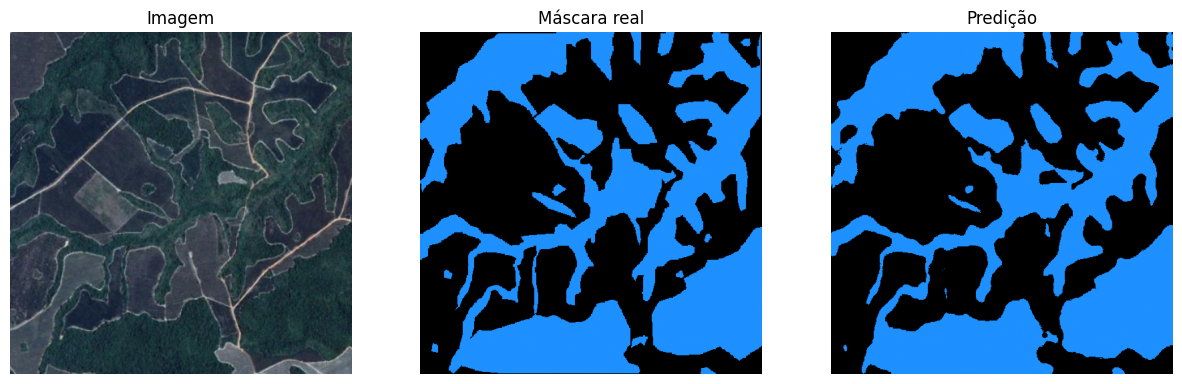

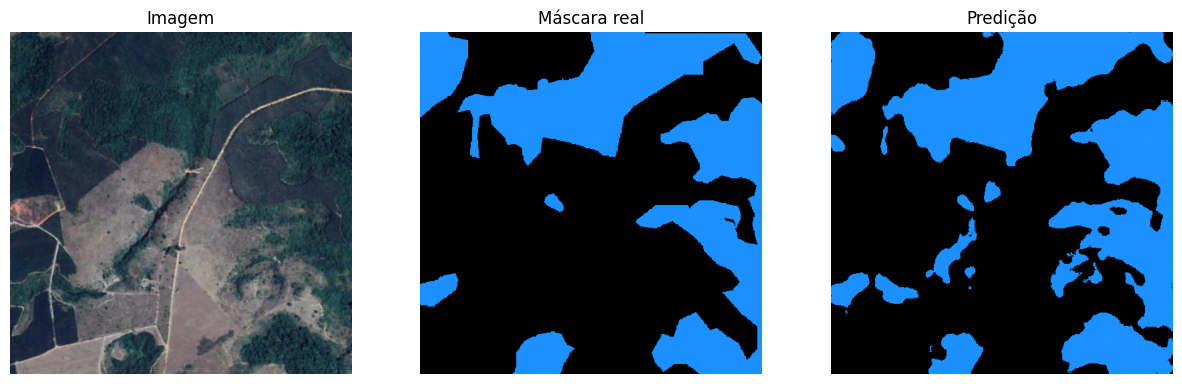

In [18]:
@torch.no_grad()
def show_predictions(model, dataset, device, num_samples=3, threshold=0.5):
    """Mostra imagem, máscara real e máscara predita para algumas amostras."""
    model.eval()

    num_samples = min(num_samples, len(dataset))

    for i in range(num_samples):
        image, mask = dataset[i]

        # Adiciona dimensão de batch e envia para o dispositivo.
        input_tensor = image.unsqueeze(0).to(device)

        # Predição.
        logits = model(input_tensor)
        prob = torch.sigmoid(logits)[0, 0].cpu().numpy()
        pred = (prob > threshold).astype(np.float32)

        # Prepara visualização.
        image_vis = denormalize_image(image)
        mask_vis = mask[0].cpu().numpy()

        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(image_vis)
        plt.title("Imagem")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(mask_vis, cmap=MASK_CMAP, vmin=0, vmax=1)
        plt.title("Máscara real")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(pred, cmap=MASK_CMAP, vmin=0, vmax=1)
        plt.title("Predição")
        plt.axis("off")

        plt.show()

# Mostra predições no conjunto de teste.
show_predictions(model, test_dataset, DEVICE, num_samples=3)